In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("All libraries imported successfully!")


All libraries imported successfully!


In [3]:
df = pd.read_csv(
    r"C:\Users\nadip\Downloads\archive (1)\train.csv"
)

print(df.head())

   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008        WD   

In [4]:
# Select the SalePrice column
print(df['SalePrice'].head())

0    208500
1    181500
2    223500
3    140000
4    250000
Name: SalePrice, dtype: int64


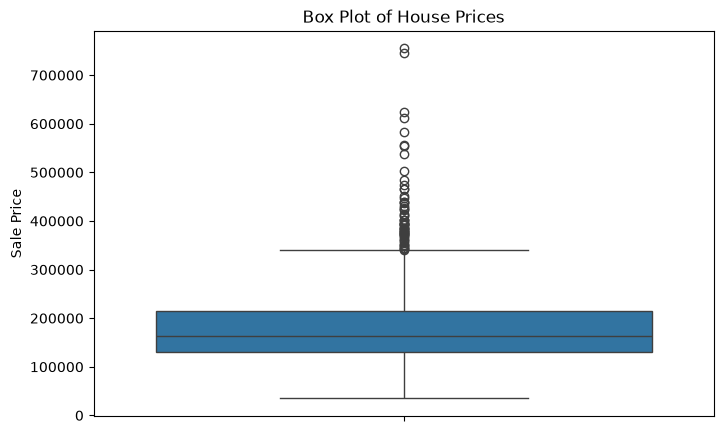

In [5]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['SalePrice'])

plt.title("Box Plot of House Prices")
plt.ylabel("Sale Price")

plt.show()

In [6]:
# Step 1: Calculate Q1 and Q3
Q1 = df['SalePrice'].quantile(0.25)
Q3 = df['SalePrice'].quantile(0.75)

print("Q1 =", Q1)
print("Q3 =", Q3)

# Step 2: Calculate IQR
IQR = Q3 - Q1
print("IQR =", IQR)

# Step 3: Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

# Step 4: Identify outliers
outliers_iqr = df[
    (df['SalePrice'] < lower_limit) |
    (df['SalePrice'] > upper_limit)
]

print("Outliers detected using IQR:")
print(outliers_iqr[['Id', 'SalePrice']])

Q1 = 129975.0
Q3 = 214000.0
IQR = 84025.0
Lower Limit = 3937.5
Upper Limit = 340037.5
Outliers detected using IQR:
        Id  SalePrice
11      12     345000
53      54     385000
58      59     438780
112    113     383970
151    152     372402
...    ...        ...
1268  1269     381000
1353  1354     410000
1373  1374     466500
1388  1389     377500
1437  1438     394617

[61 rows x 2 columns]


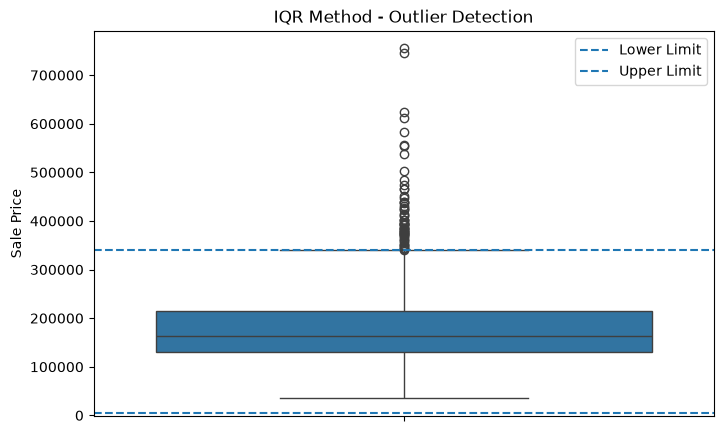

In [7]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['SalePrice'])

plt.axhline(lower_limit, linestyle='--', label='Lower Limit')
plt.axhline(upper_limit, linestyle='--', label='Upper Limit')

plt.title("IQR Method - Outlier Detection")
plt.ylabel("Sale Price")
plt.legend()

plt.show()

In [8]:
df['SalePrice_IQR_Capped'] = df['SalePrice'].clip(
    lower=lower_limit,
    upper=upper_limit
)

print(df[['SalePrice', 'SalePrice_IQR_Capped']].head(20))

    SalePrice  SalePrice_IQR_Capped
0      208500              208500.0
1      181500              181500.0
2      223500              223500.0
3      140000              140000.0
4      250000              250000.0
5      143000              143000.0
6      307000              307000.0
7      200000              200000.0
8      129900              129900.0
9      118000              118000.0
10     129500              129500.0
11     345000              340037.5
12     144000              144000.0
13     279500              279500.0
14     157000              157000.0
15     132000              132000.0
16     149000              149000.0
17      90000               90000.0
18     159000              159000.0
19     139000              139000.0


In [9]:
df['Z_score'] = stats.zscore(df['SalePrice'])

print(df[['SalePrice', 'Z_score']].head())

z_outliers = df[abs(df['Z_score']) > 3]

print("Outliers detected using Z-score:")
print(z_outliers[['Id', 'SalePrice', 'Z_score']])

df['Z_Outlier'] = abs(df['Z_score']) > 3

print(df[['SalePrice', 'Z_score', 'Z_Outlier']].head())

   SalePrice   Z_score
0     208500  0.347273
1     181500  0.007288
2     223500  0.536154
3     140000 -0.515281
4     250000  0.869843
Outliers detected using Z-score:
        Id  SalePrice   Z_score
58      59     438780  3.246967
178    179     501837  4.040982
185    186     475000  3.703050
349    350     437154  3.226492
389    390     426000  3.086040
440    441     555000  4.710413
473    474     440000  3.262329
496    497     430000  3.136409
527    528     446261  3.341168
591    592     451950  3.412804
664    665     423000  3.048264
691    692     755000  7.228819
769    770     538000  4.496348
798    799     485000  3.828970
803    804     582933  5.062146
898    899     611657  5.423840
1046  1047     556581  4.730321
1142  1143     424870  3.071811
1169  1170     625000  5.591855
1182  1183     745000  7.102899
1243  1244     465000  3.577130
1373  1374     466500  3.596018
   SalePrice   Z_score  Z_Outlier
0     208500  0.347273      False
1     181500  0.007288   

In [10]:
mean = df['SalePrice'].mean()
std = df['SalePrice'].std()

lower_z_limit = mean - 3 * std
upper_z_limit = mean + 3 * std

print("Lower Z-score limit =", lower_z_limit)
print("Upper Z-score limit =", upper_z_limit)

df['SalePrice_Z_Capped'] = df['SalePrice'].clip(
    lower=lower_z_limit,
    upper=upper_z_limit
)

print(df[['SalePrice', 'SalePrice_Z_Capped']].head(20))

Lower Z-score limit = -57406.31275824891
Upper Z-score limit = 419248.70453907084
    SalePrice  SalePrice_Z_Capped
0      208500            208500.0
1      181500            181500.0
2      223500            223500.0
3      140000            140000.0
4      250000            250000.0
5      143000            143000.0
6      307000            307000.0
7      200000            200000.0
8      129900            129900.0
9      118000            118000.0
10     129500            129500.0
11     345000            345000.0
12     144000            144000.0
13     279500            279500.0
14     157000            157000.0
15     132000            132000.0
16     149000            149000.0
17      90000             90000.0
18     159000            159000.0
19     139000            139000.0


In [11]:
print(df[
    ['SalePrice',
     'SalePrice_IQR_Capped',
     'SalePrice_Z_Capped']
].head(20))

    SalePrice  SalePrice_IQR_Capped  SalePrice_Z_Capped
0      208500              208500.0            208500.0
1      181500              181500.0            181500.0
2      223500              223500.0            223500.0
3      140000              140000.0            140000.0
4      250000              250000.0            250000.0
5      143000              143000.0            143000.0
6      307000              307000.0            307000.0
7      200000              200000.0            200000.0
8      129900              129900.0            129900.0
9      118000              118000.0            118000.0
10     129500              129500.0            129500.0
11     345000              340037.5            345000.0
12     144000              144000.0            144000.0
13     279500              279500.0            279500.0
14     157000              157000.0            157000.0
15     132000              132000.0            132000.0
16     149000              149000.0            1

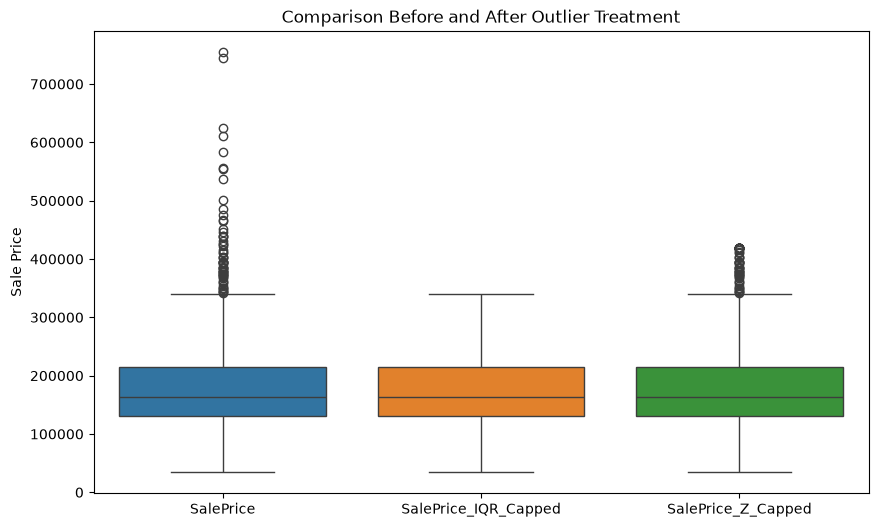

In [12]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df[
    ['SalePrice',
     'SalePrice_IQR_Capped',
     'SalePrice_Z_Capped']
])

plt.title("Comparison Before and After Outlier Treatment")
plt.ylabel("Sale Price")

plt.show()